# 03. 면적·연식·층과 가격의 관계

**질문:** 면적·연식·층은 가격과 어떤 관계가 있는가?

**방법과 지표**
- 타깃: log(㎡당 가격). 계수 b는 기준 범주 대비 ㎡당 가격 차이 (e^b−1)×100 %로 읽는다.
- **주 사양:** 구×연월 고정효과(같은 구·같은 달 거래끼리 비교) + 면적·연식·층 구간 더미. 표준오차는 **단지 클러스터**.
  - 기준 범주: 전용 60~85㎡, 연식 10~14년, 6~10층.
  - 연식·층은 비선형(재건축 기대에 따른 U자, 저층 할인)을 보려고 구간 더미로 넣는다.
- **민감도:** (a) 일괄 거래 포함 표본, (b) 취소 정보가 있는 2020-02 이후만, (c) 기간 분할(2017-11~2021-12 / 2022-01~2026-09), (d) 단지 고정효과 추가(같은 단지 안의 면적·층 차이만 사용, 연식은 제외).
- 예측 성능(그룹·시간순 분할, kNN·MLP 비교, permutation importance)은 ml-engineer 범위라 여기서 다루지 않는다.

**사용한 교재 장:** 5장 다중선형회귀.
**교재에서 바꾼 점과 이유:** 교재 5장은 연속 변수를 그대로 넣고 무작위 7:3 분할로 평가하지만, 여기서는 (1) 연식·층을 구간 더미로 넣어 비선형을 허용하고, (2) 같은 단지 거래가 반복되므로 단지 클러스터 표준오차를 쓰며, (3) 시기·지역 가격 차이를 구×연월 고정효과로 흡수했다. 목적이 예측이 아니라 연관의 크기와 불확실성을 보는 것이기 때문이다.

**주의:** 계수는 "다른 조건이 같은 거래끼리 비교했을 때의 가격 차이"(통계적 연관)이며, "층을 올리면 가격이 오른다" 같은 인과로 읽지 않는다.

In [1]:
import os
import sys
from pathlib import Path


def _find_root():
    env = os.environ.get("REANALYSIS_ROOT")
    if env:
        return Path(env).resolve()
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "AGENTS.md").exists():
            return p
    raise FileNotFoundError("AGENTS.md가 있는 프로젝트 루트를 찾지 못했습니다")


ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src" / "재검증"))
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import reanalysis_utils as ru

SEED = ru.SEED
DATA = ROOT / "data"
plt = ru.set_korean_font()

In [2]:
OUT = ru.out_dir(ROOT, "03")
tx = ru.load_tx(ROOT)
tx["gu_month"] = tx["gu"] + "|" + tx["contract_ym"]
nob = tx[tx["in_base_nobulk"]].reset_index(drop=True)
base = tx[tx["in_base"]].reset_index(drop=True)
pd.Series({"in_base_nobulk": len(nob), "in_base": len(base), "complexes": nob["complex_id"].nunique(),
           "gu_month_cells": nob["gu_month"].nunique()}).to_frame("n")

,n
in_base_nobulk,519370
in_base,523320
complexes,8818
gu_month_cells,2675


In [3]:
def run(d, refs=ru.CHAR_REFS, fe=("gu_month",), label=""):
    X = ru.dummies(d, refs).reset_index(drop=True)
    res = ru.fe_ols(d["log_ppa"].to_numpy(), X, [d[f].to_numpy() for f in fe], clusters=d["complex_id"].to_numpy())
    ct = ru.coef_table(res)
    ct["pct"] = (np.exp(ct["coef"]) - 1) * 100
    ct["pct_lo"] = (np.exp(ct["ci_low"]) - 1) * 100
    ct["pct_hi"] = (np.exp(ct["ci_high"]) - 1) * 100
    ct["spec"] = label
    ct["n"] = res["n"]
    ct["n_clusters"] = res["n_clusters"]
    ct["r2_within"] = res["r2_within"]
    return ct, res


specs = {}
specs["main"], res_main = run(nob, label="주 사양(일괄 제외)")
specs["incl_bulk"], _ = run(base, label="일괄 포함")
specs["post2020_02"], _ = run(nob[nob["contract_ym"] >= "2020-02"].reset_index(drop=True), label="2020-02 이후")
specs["p2017_2021"], _ = run(nob[nob["contract_ym"] <= "2021-12"].reset_index(drop=True), label="2017-11~2021-12")
specs["p2022_2026"], _ = run(nob[nob["contract_ym"] >= "2022-01"].reset_index(drop=True), label="2022-01~2026-09")
specs["complex_fe"], _ = run(nob, refs=ru.CHAR_REFS_NOAGE, fe=("gu_month", "complex_id"), label="단지 FE 추가")
allc = pd.concat(specs.values(), ignore_index=True)
allc["var"] = allc["term"].str.split("=").str[0]
allc["bin"] = allc["term"].str.split("=").str[1]
pd.DataFrame({k: {"n": v["n"].iloc[0], "clusters": v["n_clusters"].iloc[0], "r2_within": v["r2_within"].iloc[0]}
              for k, v in specs.items()}).T

,n,clusters,r2_within
main,519370.0,8818.0,0.224744
incl_bulk,523320.0,8908.0,0.222849
post2020_02,341160.0,8483.0,0.229883
p2017_2021,293162.0,8286.0,0.232202
p2022_2026,226208.0,7738.0,0.253573
complex_fe,519370.0,8818.0,0.460978


`r2_within`은 구×연월 평균을 뺀 뒤 면적·연식·층 구간이 설명하는 분산 비율이다(단지 FE 사양은 단지 평균까지 뺀 뒤의 값이라 직접 비교하지 않는다).

In [4]:
main = specs["main"][["term", "pct", "pct_lo", "pct_hi", "p_value"]]
main.round(2)

,term,pct,pct_lo,pct_hi,p_value
0,area_bin=000-040,-5.80,-9.93,-1.49,0.01
1,area_bin=040-060,13.45,11.98,14.93,0.00
2,area_bin=085-102,-0.97,-4.61,2.82,0.61
3,area_bin=102-135,-10.62,-12.01,-9.21,0.00
4,area_bin=135+,-14.44,-17.37,-11.41,0.00
5,age_bin=00-04,25.30,21.44,29.27,0.00
6,age_bin=05-09,13.90,10.92,16.97,0.00
7,age_bin=15-19,-9.55,-11.04,-8.04,0.00
8,age_bin=20-24,-13.72,-15.99,-11.38,0.00
9,age_bin=25-29,-10.14,-12.82,-7.37,0.00


위 표는 주 사양의 구간별 ㎡당 가격 차이(%)와 단지 클러스터 95% 신뢰구간이다. 기준은 60~85㎡, 연식 10~14년, 6~10층이다.

In [5]:
cmp = allc.pivot_table(index="term", columns="spec", values="pct").round(1)
cmp = cmp[["주 사양(일괄 제외)", "일괄 포함", "2020-02 이후", "2017-11~2021-12", "2022-01~2026-09", "단지 FE 추가"]]
cmp

spec,주 사양(일괄 제외),일괄 포함,2020-02 이후,2017-11~2021-12,2022-01~2026-09,단지 FE 추가
term,,,,,,
age_bin=00-04,25.3,24.4,21.8,25.5,22.3,NaN
age_bin=05-09,13.9,13.8,12.3,8.9,17.8,NaN
age_bin=15-19,-9.6,-9.6,-10.0,-12.6,-2.7,NaN
age_bin=20-24,-13.7,-13.7,-16.2,-12.3,-16.7,NaN
age_bin=25-29,-10.1,-10.1,-13.7,-6.5,-14.8,NaN
age_bin=30-34,-1.0,-1.1,-5.6,4.9,-9.2,NaN
age_bin=35+,11.1,11.1,6.7,15.8,6.4,NaN
area_bin=000-040,-5.8,-5.8,-11.2,0.7,-13.2,19.4
area_bin=040-060,13.4,13.3,13.7,13.0,14.0,16.1


사양별로 같은 구간의 계수(%)를 비교한 표다. 단지 FE 사양에는 연식이 없다(같은 단지 안에서 연식은 시간과 함께만 변해 구×연월 FE와 겹친다). 단지 FE 사양의 면적 계수는 같은 단지 안 다른 평형 간 차이, 층 계수는 같은 단지 안 다른 층 간 차이다.

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), sharey=True)
for ax_, var, lab, ref in [(axes[0], "area_bin", "전용면적 구간(㎡)", ru.AREA_REF), (axes[1], "age_bin", "연식 구간(년)", ru.AGE_REF),
                           (axes[2], "floor_bin", "층 구간", ru.FLOOR_REF)]:
    s = allc[(allc["spec"] == "주 사양(일괄 제외)") & (allc["var"] == var)][["bin", "pct", "pct_lo", "pct_hi"]]
    s = pd.concat([s, pd.DataFrame([{"bin": ref, "pct": 0, "pct_lo": 0, "pct_hi": 0}])]).sort_values("bin")
    if var == "floor_bin":
        order = ["B", "01", "02", "03-05", "06-10", "11-15", "16-20", "21-30", "31+"]
        s = s.set_index("bin").reindex(order).reset_index()
    ax_.errorbar(range(len(s)), s["pct"], yerr=[s["pct"] - s["pct_lo"], s["pct_hi"] - s["pct"]], fmt="o-", capsize=3)
    ax_.axhline(0, color="grey", lw=0.8)
    ax_.set_xticks(range(len(s)))
    ax_.set_xticklabels(s["bin"], rotation=45, fontsize=8)
    ax_.set_xlabel(lab)
axes[0].set_ylabel("기준 대비 ㎡당 가격 차이(%)")
fig.suptitle("면적·연식·층 구간별 ㎡당 가격 차이, 구×연월 FE (2017-11~2026-09)", fontsize=11)
fig.text(0.01, -0.03, f"n={len(nob):,}건, 단지 {res_main['n_clusters']:,}개 클러스터 95% CI. 자료: outputs/재검증/03/fig_coef_bins.csv", fontsize=8)
fig.tight_layout()
ru.save_png(fig, OUT, "fig_coef_bins.png")
plt.close(fig)

## 2. 저장

In [7]:
ru.save_chart_csv(allc[["spec", "var", "bin", "term", "coef", "se", "p_value", "pct", "pct_lo", "pct_hi", "n", "n_clusters", "r2_within"]],
                  OUT, "fig_coef_bins.csv")
samp = nob.sample(n=5000, random_state=SEED)[["gu", "contract_ym", "area_m2", "age", "floor", "ppa_manwon"]]
ru.save_chart_csv(samp, OUT, "fig_scatter_sample.csv")
cell = (nob.groupby(["area_bin", "age_bin"]).agg(n=("row_id", "size"), median_ppa=("ppa_manwon", "median")).reset_index())
ru.save_chart_csv(cell, OUT, "fig_area_age_cells.csv")

rows = []
P0, P1 = "2017-11", "2026-09"


def add(key, label, value, unit, n, note, src="fig_coef_bins.csv", claim="통계적 연관", ps=P0, pe=P1):
    rows.append({"key": key, "label": label, "value": float(value), "unit": unit, "sample_n": int(n),
                 "period": f"{ps}~{pe}", "period_start": ps, "period_end": pe, "split_type": "없음",
                 "claim_level": claim, "source_file": src, "note": note})


m = specs["main"].set_index("term")
pick = [("area_bin=000-040", "area_le40", "전용 40㎡ 이하(기준 60~85㎡)"), ("area_bin=135+", "area_gt135", "전용 135㎡ 초과(기준 60~85㎡)"),
        ("age_bin=00-04", "age_0_4", "연식 0~4년(기준 10~14년)"), ("age_bin=20-24", "age_20_24", "연식 20~24년(기준 10~14년)"),
        ("age_bin=30-34", "age_30_34", "연식 30~34년(기준 10~14년)"), ("age_bin=35+", "age_35p", "연식 35년 이상(기준 10~14년)"),
        ("floor_bin=01", "floor_1", "1층(기준 6~10층)"), ("floor_bin=21-30", "floor_21_30", "21~30층(기준 6~10층)"),
        ("floor_bin=31+", "floor_31p", "31층 이상(기준 6~10층)")]
for term, key, lab in pick:
    r = m.loc[term]
    add(f"coef_{key}_pct", f"{lab} ㎡당 가격 차이", r["pct"], "%", r["n"],
        f"95% CI {r['pct_lo']:.1f}~{r['pct_hi']:.1f}, 단지 클러스터 {int(r['n_clusters']):,}개, 구×연월 FE")
cf = specs["complex_fe"].set_index("term")
for term, key, lab in [("floor_bin=01", "floor_1", "1층"), ("floor_bin=21-30", "floor_21_30", "21~30층"), ("area_bin=135+", "area_gt135", "135㎡ 초과")]:
    r = cf.loc[term]
    add(f"coef_cxfe_{key}_pct", f"단지 FE 사양 {lab} ㎡당 가격 차이", r["pct"], "%", r["n"],
        f"같은 단지 안 비교, 95% CI {r['pct_lo']:.1f}~{r['pct_hi']:.1f}")
for k_, v in specs.items():
    add(f"r2_within_{k_}", f"{v['spec'].iloc[0]} within R²", v["r2_within"].iloc[0], "R²", v["n"].iloc[0], "같은 표본 적합도(예측 성능 아님)",
        claim="통계적 연관", ps="2020-02" if k_ == "post2020_02" else ("2022-01" if k_ == "p2022_2026" else P0),
        pe="2021-12" if k_ == "p2017_2021" else P1)
summary = ru.save_summary(rows, OUT)
ru.save_meta({
    "question": "면적·연식·층은 가격과 어떤 관계가 있는가?",
    "method": "log(㎡당 가격) ~ 구×연월 FE + 면적·연식·층 구간 더미, 단지 클러스터 SE. 민감도: 일괄 포함, 2020-02 이후, 기간 분할, 단지 FE",
    "textbook_chapters": ["5장 다중선형회귀"],
    "sample_period": "2017-11~2026-09", "sample_size": {"in_base_nobulk": len(nob), "complexes": int(res_main["n_clusters"])},
    "data_files": ["outputs/재검증/00_정제/transactions.parquet"],
    "limitations": ["계수는 통계적 연관이며 인과가 아니다", "관측되지 않은 단지 특성(브랜드·재건축 진행·조망 등)이 면적·연식과 얽혀 있다",
                    "연식 계수는 '노후 감가'와 '재건축 기대'가 섞인 값", "예측 성능은 ml-engineer 범위", "2020-02 이전 취소 정보 없음, 2026-08~09 잠정"],
}, OUT)
summary[["key", "value", "note"]]

,key,value,note
0,coef_area_le40_pct,-5.803319,"95% CI -9.9~-1.5, 단지 클러스터 8,818개, 구×연월 FE"
1,coef_area_gt135_pct,-14.442123,"95% CI -17.4~-11.4, 단지 클러스터 8,818개, 구×연월 FE"
2,coef_age_0_4_pct,25.295906,"95% CI 21.4~29.3, 단지 클러스터 8,818개, 구×연월 FE"
3,coef_age_20_24_pct,-13.715685,"95% CI -16.0~-11.4, 단지 클러스터 8,818개, 구×연월 FE"
4,coef_age_30_34_pct,-1.018787,"95% CI -4.6~2.7, 단지 클러스터 8,818개, 구×연월 FE"
5,coef_age_35p_pct,11.068088,"95% CI 5.2~17.2, 단지 클러스터 8,818개, 구×연월 FE"
6,coef_floor_1_pct,-7.415092,"95% CI -8.3~-6.6, 단지 클러스터 8,818개, 구×연월 FE"
7,coef_floor_21_30_pct,18.293401,"95% CI 15.7~21.0, 단지 클러스터 8,818개, 구×연월 FE"
8,coef_floor_31p_pct,30.627897,"95% CI 24.6~37.0, 단지 클러스터 8,818개, 구×연월 FE"
9,coef_cxfe_floor_1_pct,-7.440654,"같은 단지 안 비교, 95% CI -7.6~-7.2"


## 결론
모든 수치는 주 사양(구×연월 FE, 일괄 거래 제외, n=519,370건, 2017-11~2026-09, 단지 8,818개 클러스터 95% CI)의 통계적 연관이다(`fig_coef_bins.csv`, `summary.csv`).
- **연식(U자):** 연식 10~14년 대비 ㎡당 가격은 0~4년 +25.3%(CI 21.4~29.3), 20~24년 −13.7%(−16.0~−11.4)로 내려갔다가 30~34년 −1.0%(−4.6~2.7, 차이 없음), 35년 이상 +11.1%(5.2~17.2)로 다시 올랐다. 오래된 단지일수록 재건축 기대가 가격에 함께 반영된 것과 맞는 모양이다.
- **면적:** 60~85㎡ 대비 40~60㎡는 +13.4%, 102~135㎡ −10.6%, 135㎡ 초과 −14.4%로 ㎡당 가격은 중소형이 높았다. 40㎡ 이하는 −5.8%(CI −9.9~−1.5)이고 기간에 따라 부호가 바뀌었다(2017~2021 +0.7%, 2022~2026 −13.2%).
- **층:** 6~10층 대비 1층 −7.4%, 21~30층 +18.3%, 31층 이상 +30.6%였다. 그러나 **같은 단지 안에서만 비교하면(단지 FE)** 1층 −7.4%는 그대로였지만 21~30층은 +1.6%, 31층 이상은 +5.3%로 크게 줄었다. 고층 할증의 대부분은 "층" 자체보다 고층 건물이 있는 단지(신축·초고층)의 차이와 함께 나타난 것이다.
- **안정성:** 일괄 거래 포함, 2020-02 이후, 기간 분할에서도 층·면적 계수의 부호와 크기는 대체로 비슷했다. 연식 15~34년 계수는 기간에 따라 크기가 달랐다(예: 30~34년 2017~2021 +4.9%, 2022~2026 −9.2%).
- 면적·연식·층 구간은 구×연월 평균을 뺀 가격 변동의 약 22%를 설명했다(within R² 0.225). 나머지는 단지·입지 차이다.

## 한계
- 계수는 같은 구·같은 달 거래끼리 비교한 연관이며 인과가 아니다. 브랜드·재건축 사업 단계·조망·대지지분 같은 단지 특성이 면적·연식·층과 얽혀 있다(단지 FE 사양에서 층 계수가 크게 줄어든 것이 그 예다).
- 연식 계수는 노후 감가와 재건축 기대가 섞인 값이며, 둘을 나누지 못한다.
- 지하층(B)은 120건뿐이라 신뢰구간이 넓다.
- 예측 성능(단지 그룹·시간순 분할)은 ml-engineer 범위다. 여기 R²는 같은 표본 적합도다.
- 2020-02 이전 취소 정보가 없고, 2026-08~09는 잠정 월이다.

## 시각화 (발표용): 연식별·층별 ㎡당 가격 차이

`fig_coef_bins.csv`의 회귀 계수(같은 구·같은 달 거래끼리 비교, 단지 클러스터 95% 신뢰구간)로 그린다.
- 연식 그림의 기준은 10~14년(0%)이다.
- 층 그림의 기준은 6~10층(0%)이고, 같은 단지 안 비교(단지 고정효과 추가)를 함께 그렸다. 지하층(B)은 거래가 적어 뺐다.

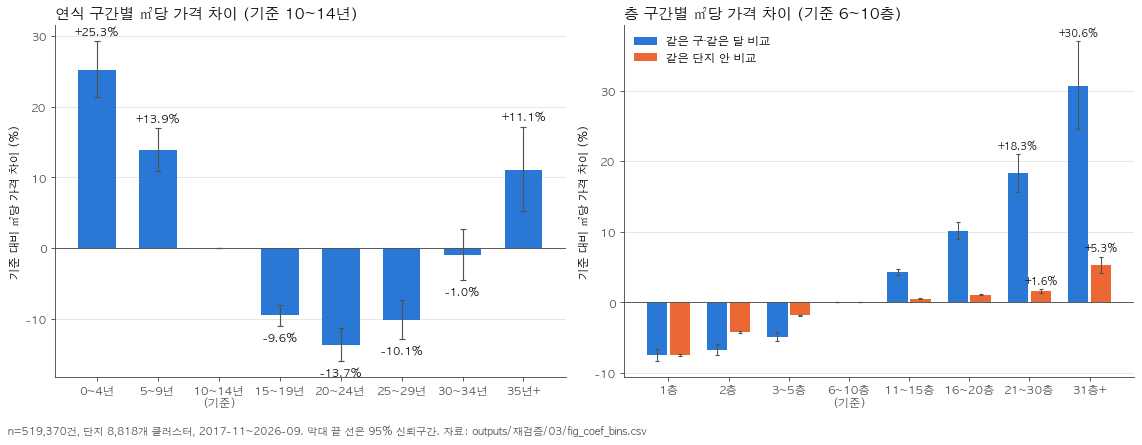

In [8]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import font_manager

_fonts = {f.name for f in font_manager.fontManager.ttflist}
for _name in ["AppleGothic", "NanumGothic", "Malgun Gothic"]:
    if _name in _fonts:
        plt.rcParams["font.family"] = _name
        break
plt.rcParams["axes.unicode_minus"] = False
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # 범주 색 고정 순서
INK, INK2, GRID, BAND = "#0b0b0b", "#52514e", "#e6e5e1", "#f0efec"


def style(ax, grid="y"):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(INK2)
    ax.tick_params(colors=INK2)
    if grid:
        ax.grid(axis=grid, color=GRID, lw=0.8)
    ax.set_axisbelow(True)


def save(fig, name):
    """폭 1200px 이하 PNG로 저장하고 노트북에 표시한다(이 노트북은 Agg 백엔드라 plt.show()로는 보이지 않음)."""
    from IPython.display import Image, display
    w = fig.get_size_inches()[0]
    fig.savefig(OUT / name, dpi=min(110, 1150 / w), bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(OUT / name)))

OUT = ROOT / "outputs" / "재검증" / "03"
c = pd.read_csv(OUT / "fig_coef_bins.csv", dtype={"bin": str})
main = c[c["spec"] == "주 사양(일괄 제외)"]
cfe = c[c["spec"] == "단지 FE 추가"]
n_main, n_cl = int(main["n"].iloc[0]), int(main["n_clusters"].iloc[0])


def with_ref(df, var, ref, order):
    x = df[df["var"] == var][["bin", "pct", "pct_lo", "pct_hi"]]
    x = pd.concat([x, pd.DataFrame([{"bin": ref, "pct": 0.0, "pct_lo": 0.0, "pct_hi": 0.0}])])
    return x.set_index("bin").loc[order].reset_index()


age_order = ["00-04", "05-09", "10-14", "15-19", "20-24", "25-29", "30-34", "35+"]
age_lab = ["0~4년", "5~9년", "10~14년\n(기준)", "15~19년", "20~24년", "25~29년", "30~34년", "35년+"]
fl_order = ["01", "02", "03-05", "06-10", "11-15", "16-20", "21-30", "31+"]
fl_lab = ["1층", "2층", "3~5층", "6~10층\n(기준)", "11~15층", "16~20층", "21~30층", "31층+"]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.2))
a = with_ref(main, "age_bin", "10-14", age_order)
x = np.arange(len(a))
a1.bar(x, a["pct"], color=[SERIES[0] if b != "10-14" else GRID for b in a["bin"]], width=0.62)
a1.errorbar(x, a["pct"], yerr=[a["pct"] - a["pct_lo"], a["pct_hi"] - a["pct"]], fmt="none", ecolor=INK2, capsize=3, lw=1)
for xi, v, lo, hi, b in zip(x, a["pct"], a["pct_lo"], a["pct_hi"], a["bin"]):
    if b != "10-14":
        a1.annotate(f"{v:+.1f}%", (xi, hi if v >= 0 else lo), xytext=(0, 5 if v >= 0 else -14),
                    textcoords="offset points", ha="center", fontsize=9.5, color=INK)
a1.axhline(0, color=INK2, lw=0.8)
a1.set_xticks(x, age_lab)
a1.set_ylabel("기준 대비 ㎡당 가격 차이 (%)")
a1.set_title("연식 구간별 ㎡당 가격 차이 (기준 10~14년)", loc="left", fontsize=13, color=INK)
style(a1)

f1 = with_ref(main, "floor_bin", "06-10", fl_order)
f2 = with_ref(cfe, "floor_bin", "06-10", fl_order)
x = np.arange(len(f1))
w = 0.38
for off, df, col, lab in [(-w / 2, f1, SERIES[0], "같은 구·같은 달 비교"), (w / 2, f2, SERIES[1], "같은 단지 안 비교")]:
    a2.bar(x + off, df["pct"], width=w - 0.04, color=col, label=lab)
    a2.errorbar(x + off, df["pct"], yerr=[df["pct"] - df["pct_lo"], df["pct_hi"] - df["pct"]],
                fmt="none", ecolor=INK2, capsize=2, lw=0.9)
for df, off in [(f1, -w / 2), (f2, w / 2)]:
    for xi, (b, v, lo, hi) in zip(x, df[["bin", "pct", "pct_lo", "pct_hi"]].itertuples(index=False)):
        if b in ("21-30", "31+"):
            a2.annotate(f"{v:+.1f}%", (xi + off, hi if v >= 0 else lo), xytext=(0, 4 if v >= 0 else -13),
                        textcoords="offset points", ha="center", fontsize=8.5, color=INK)
a2.axhline(0, color=INK2, lw=0.8)
a2.set_xticks(x, fl_lab)
a2.set_ylabel("기준 대비 ㎡당 가격 차이 (%)")
a2.set_title("층 구간별 ㎡당 가격 차이 (기준 6~10층)", loc="left", fontsize=13, color=INK)
a2.legend(loc="upper left", frameon=False)
style(a2)
fig.text(0.01, -0.03, f"n={n_main:,}건, 단지 {n_cl:,}개 클러스터, 2017-11~2026-09. 막대 끝 선은 95% 신뢰구간. "
         "자료: outputs/재검증/03/fig_coef_bins.csv", fontsize=9, color=INK2)
fig.tight_layout()
save(fig, "viz_03_age_floor.png")
